In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(7)
print('Libraries imported successfully.')

Libraries imported successfully.


In [2]:
rng = np.random.default_rng(7)
X = rng.uniform(-1, 1, size=(100, 2))
y = (1.2 * X[:, 0] - 0.9 * X[:, 1] + 0.1 > 0).astype(int)

def step_activation(z):
    return (z >= 0).astype(int)

weights = np.zeros(2)
bias = 0.0
learning_rate = 0.1
max_epochs = 1000
errors_per_epoch = []

for epoch in range(max_epochs):
    errors = 0
    for xi, target in zip(X, y):
        prediction = int(np.dot(xi, weights) + bias >= 0)
        error = target - prediction
        if error != 0:
            weights += learning_rate * error * xi
            bias += learning_rate * error
            errors += 1
    errors_per_epoch.append(errors)
    if errors == 0:
        break

predictions = step_activation(X @ weights + bias)
accuracy = np.mean(predictions == y)
print('Dataset shape:', X.shape)
print('Class counts (Rejected=0, Approved=1):', np.bincount(y))
print(f'Converged after {epoch + 1} epochs.')
print('Final weights:', np.round(weights, 4))
print(f'Final bias: {bias:.4f}')
print(f'Training accuracy: {accuracy * 100:.2f}%')

Dataset shape: (100, 2)
Class counts (Rejected=0, Approved=1): [48 52]
Converged after 107 epochs.
Final weights: [ 1.1205 -0.8279]
Final bias: 0.1000
Training accuracy: 100.00%


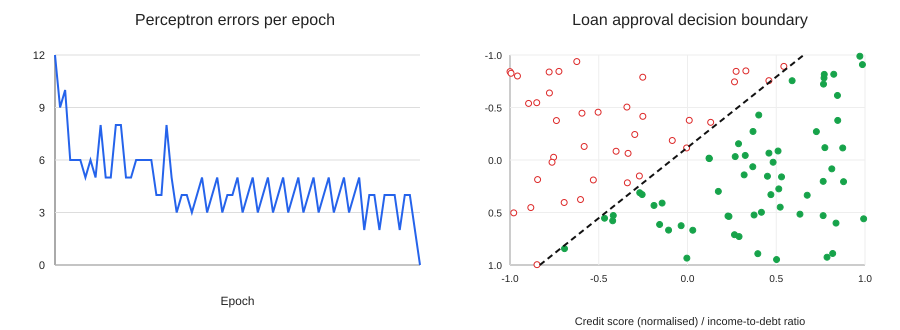

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(range(1, len(errors_per_epoch) + 1), errors_per_epoch, marker='o')
axes[0].set_title('Perceptron errors per epoch')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Number of misclassified samples')
axes[0].grid(True)

axes[1].scatter(X[y == 0, 0], X[y == 0, 1], label='Rejected (0)', marker='x')
axes[1].scatter(X[y == 1, 0], X[y == 1, 1], label='Approved (1)', marker='o')
x_line = np.linspace(-1, 1, 200)
if abs(weights[1]) > 1e-12:
    y_line = -(weights[0] * x_line + bias) / weights[1]
    axes[1].plot(x_line, y_line, 'k--', label='Decision boundary')
axes[1].set_xlim(-1.05, 1.05)
axes[1].set_ylim(-1.05, 1.05)
axes[1].set_xlabel('Credit score (normalised)')
axes[1].set_ylabel('Income-to-debt ratio (normalised)')
axes[1].set_title('Loan approval decision boundary')
axes[1].legend()
axes[1].grid(True)
plt.tight_layout()
plt.show()

In [4]:
X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
y_xor = np.array([0, 1, 1, 0])
w_xor = np.zeros(2)
b_xor = 0.0

for _ in range(20):
    for xi, target in zip(X_xor, y_xor):
        prediction = int(np.dot(xi, w_xor) + b_xor >= 0)
        error = target - prediction
        w_xor += 0.1 * error * xi
        b_xor += 0.1 * error

xor_predictions = step_activation(X_xor @ w_xor + b_xor)
xor_accuracy = np.mean(xor_predictions == y_xor)
print('XOR targets:', y_xor)
print('Perceptron predictions:', xor_predictions)
print(f'XOR accuracy: {xor_accuracy * 100:.2f}%')

XOR targets: [0 1 1 0]
Perceptron predictions: [1 1 0 0]
XOR accuracy: 50.00%


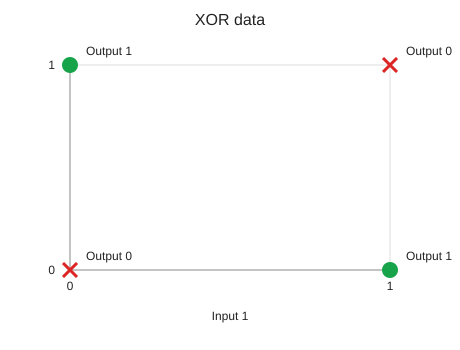

In [5]:
plt.figure(figsize=(5, 4))
for point, label in zip(X_xor, y_xor):
    plt.scatter(point[0], point[1], s=140, marker='o' if label else 'x', label=f'Output {label}')
plt.title('XOR data')
plt.xlabel('Input 1')
plt.ylabel('Input 2')
plt.xticks([0, 1])
plt.yticks([0, 1])
plt.grid(True)
plt.show()

In [6]:
z = np.array([-2., -1., 0., 1., 2.])
sigmoid = 1 / (1 + np.exp(-z))
relu = np.maximum(0, z)
step = step_activation(z)

print('Input values:', z)
print('Step:', step)
print('Sigmoid:', np.round(sigmoid, 4))
print('ReLU:', relu)

Input values: [-2. -1.  0.  1.  2.]
Step: [0 0 1 1 1]
Sigmoid: [0.1192 0.2689 0.5    0.7311 0.8808]
ReLU: [0. 0. 0. 1. 2.]


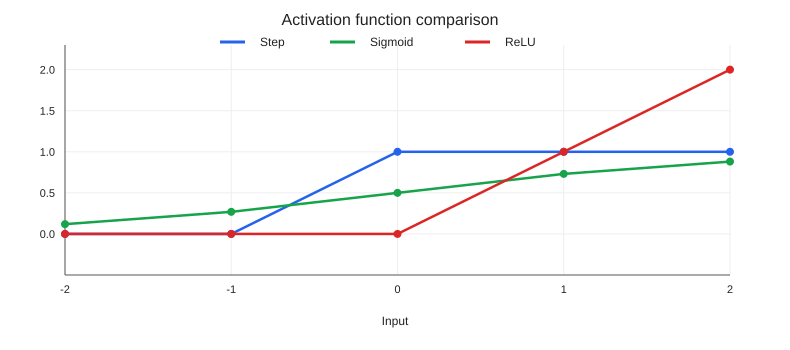

In [7]:
plt.figure(figsize=(8, 5))
plt.plot(z, step, marker='o', label='Step')
plt.plot(z, sigmoid, marker='o', label='Sigmoid')
plt.plot(z, relu, marker='o', label='ReLU')
plt.title('Activation function comparison')
plt.xlabel('Input')
plt.ylabel('Output')
plt.grid(True)
plt.legend()
plt.show()